In [428]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
  
# Load the dataset  
df = pd.read_csv('./data/mini_project_2_data.csv')

In [429]:
df.head()

,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children
0,94113,0.0,Changi,November,June,25.0,June,27.0,Singapore,Yes,Single,SGD$ 492.98,Website,1,0.0
1,86543,0.0,Orchard,August,November,28.0,November,29.0,Indonesia,Yes,King,SGD$ 1351.22,Website,2,0.0
2,75928,0.0,Changi,March,February,7.0,February,11.0,India,Yes,Single,NaN,Agent,1,0.0
3,66947,1.0,Orchard,September,October,1.0,October,3.0,China,Yes,Single,SGD$ 666.04,Website,1,0.0
4,106390,0.0,Orchard,March,June,20.0,June,24.0,Australia,Yes,Queen,USD$ 665.37,Website,1,0.0


- price to be feature engineered

In [430]:
df['currency'] = df['price'].str.extract(r'^(\D+)')[0].str.strip()

# See the unique currencies and how often each appears
print(df['currency'].unique())
print(df['currency'].value_counts(dropna=False))

['SGD$' nan 'USD$']
currency
SGD$    47295
USD$    47214
NaN     24882
Name: count, dtype: int64


Price is in SGD or USD only.

In [431]:
def convert_to_sgd(price: str, usd_to_sgd=1.35) -> float:
    """
    Convert a price string like 'USD$ 658.23' or 'SGD$ 492.98' to a float in SGD.
    Null values are returned as NaN.

    Args:
        price (str): A string representing the price in USD or SGD, in the format 'CCC$ XXX.XX' where CCC is currency

    Returns:
        float: The price value in SGD without currency prefix, rounded to 2 decimal places.

    Example:
        convert_storey_range('USD$ 658.23') -> 888.62

    """
    if pd.isna(price):
        return float('nan')

    price = str(price).strip()
    amount = float(price.split()[-1].replace(',', ''))   # numeric part after the prefix

    if price.startswith('USD'):
        amount *= usd_to_sgd

    return round(amount, 2)

df['price'] = df['price'].apply(convert_to_sgd)

In [432]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119391 entries, 0 to 119390
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   booking_id      119391 non-null  int64  
 1   no_show         119390 non-null  float64
 2   branch          119390 non-null  object 
 3   booking_month   119390 non-null  object 
 4   arrival_month   119390 non-null  object 
 5   arrival_day     119390 non-null  float64
 6   checkout_month  119390 non-null  object 
 7   checkout_day    119390 non-null  float64
 8   country         119390 non-null  object 
 9   first_time      119390 non-null  object 
 10  room            97778 non-null   object 
 11  price           94509 non-null   float64
 12  platform        119390 non-null  object 
 13  num_adults      119390 non-null  object 
 14  num_children    119390 non-null  float64
 15  currency        94509 non-null   object 
dtypes: float64(5), int64(1), object(10)
memory usage: 14.6+ 

In [433]:
df.isnull().sum()

booking_id            0
no_show               1
branch                1
booking_month         1
arrival_month         1
arrival_day           1
checkout_month        1
checkout_day          1
country               1
first_time            1
room              21613
price             24882
platform              1
num_adults            1
num_children          1
currency          24882
dtype: int64

In [434]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
booking_id,119391.0,59695.000000,34465.357332,0.00,29847.50,59695.00,89542.50,119390.00
no_show,119390.0,0.370416,0.482918,0.00,0.00,0.00,1.00,1.00
arrival_day,119390.0,15.798241,8.780829,1.00,8.00,16.00,23.00,31.00
checkout_day,119390.0,14.250507,11.063697,-31.00,7.00,15.00,23.00,31.00
price,94509.0,942.242586,264.061121,394.21,818.12,905.81,998.62,2099.96
num_children,119390.0,0.871229,0.779796,0.00,0.00,1.00,1.00,3.00


- Negative values for checkout_day

In [435]:
df.duplicated().sum()

0

In [436]:
# show the entire rows where no_show is null
df[df['no_show'].isna()]

,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children,currency
111598,115536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [437]:
# drop unusable row
df = df.dropna(subset=['no_show'])

# verify changes
df.isnull().sum()

booking_id            0
no_show               0
branch                0
booking_month         0
arrival_month         0
arrival_day           0
checkout_month        0
checkout_day          0
country               0
first_time            0
room              21612
price             24881
platform              0
num_adults            0
num_children          0
currency          24881
dtype: int64

Creating Bar Chart
---------

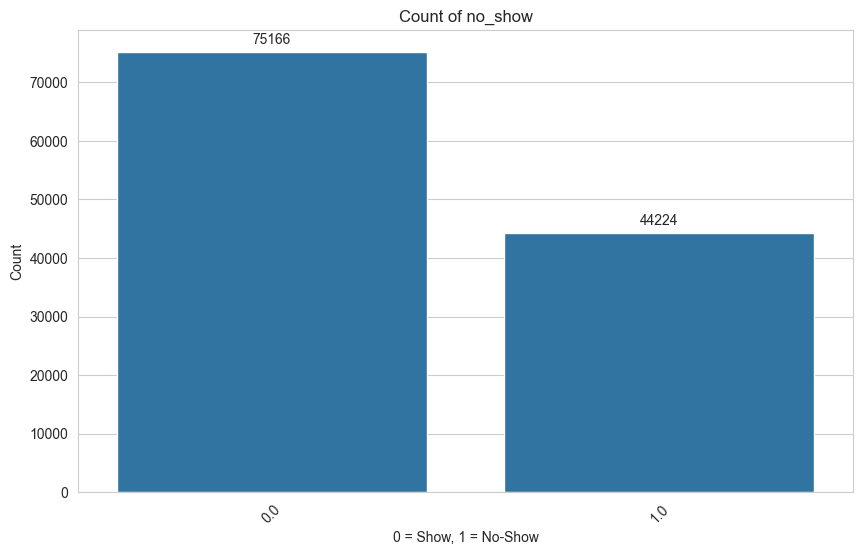

In [438]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for If the customer is a No-Show with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='no_show', data=df)
plt.title('Count of no_show')
plt.xlabel('0 = Show, 1 = No-Show')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

- Mild inbalance dataset

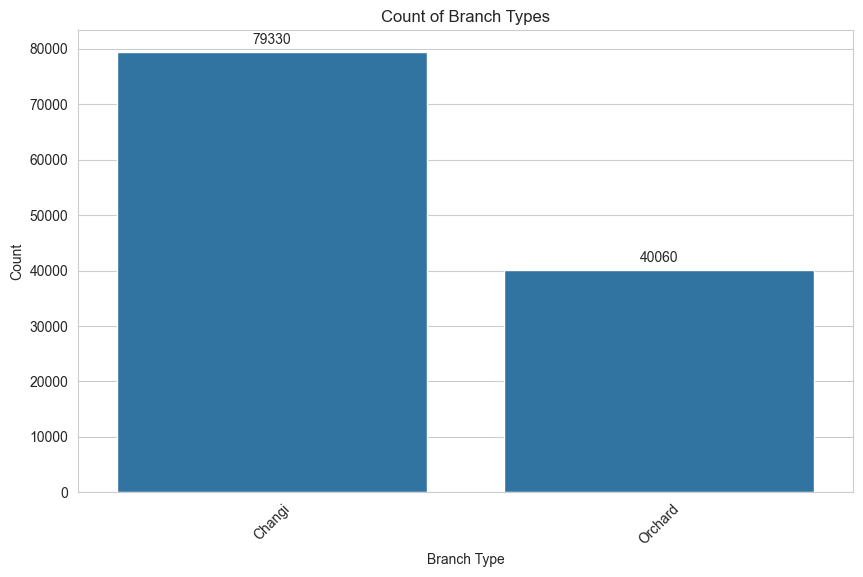

In [439]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for branch type with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='branch', data=df)
plt.title('Count of Branch Types')
plt.xlabel('Branch Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

- Only 2 branches
- Changi is more common than Orchard

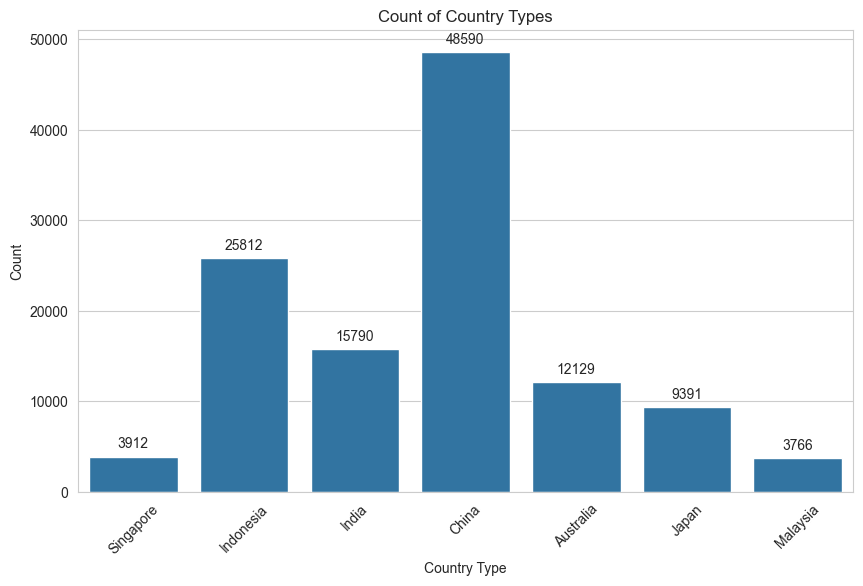

In [440]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for country type with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='country', data=df)
plt.title('Count of Country Types')
plt.xlabel('Country Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

Most common country is China, followed by Indonesia

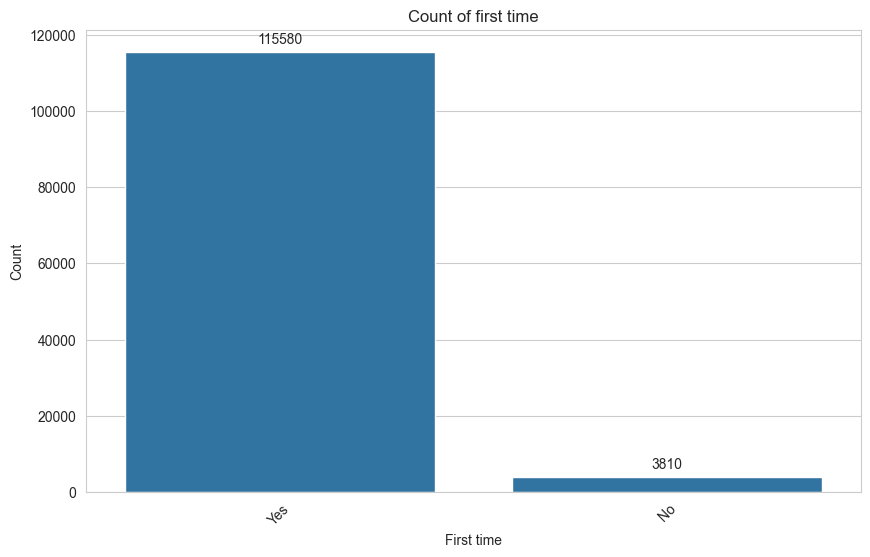

In [441]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for first time with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='first_time', data=df)
plt.title('Count of first time')
plt.xlabel('First time')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

Mostly first time customers

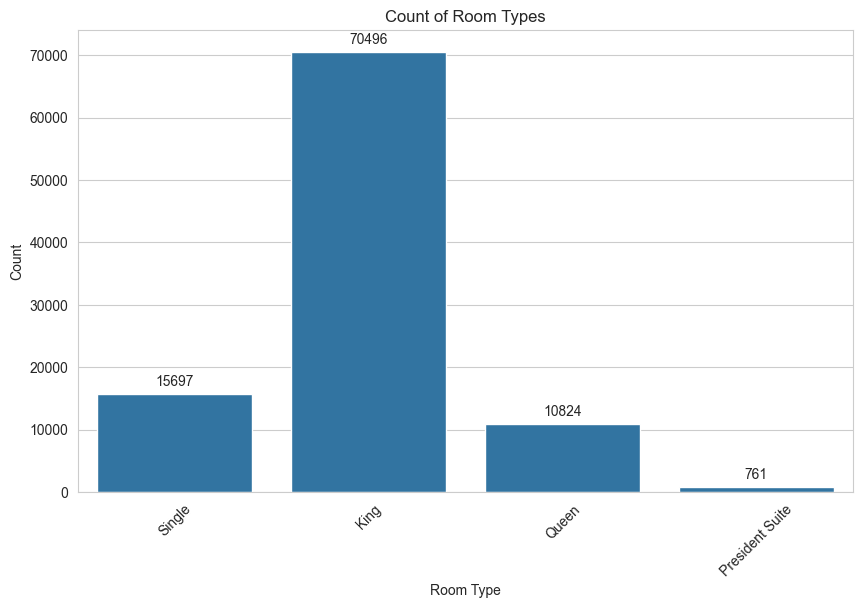

In [442]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for room type with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='room', data=df)
plt.title('Count of Room Types')
plt.xlabel('Room Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

Most common room is King

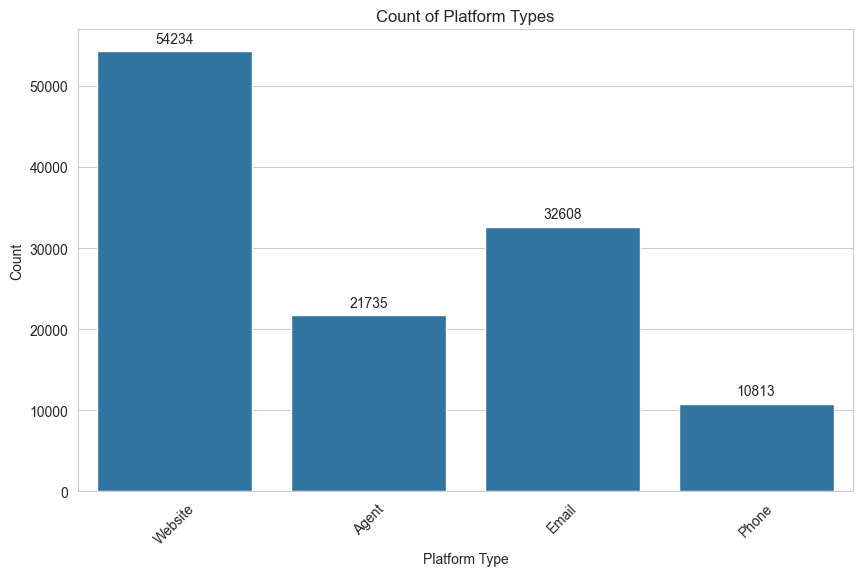

In [443]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for platform type with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='platform', data=df)
plt.title('Count of Platform Types')
plt.xlabel('Platform Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

Most common platform is website

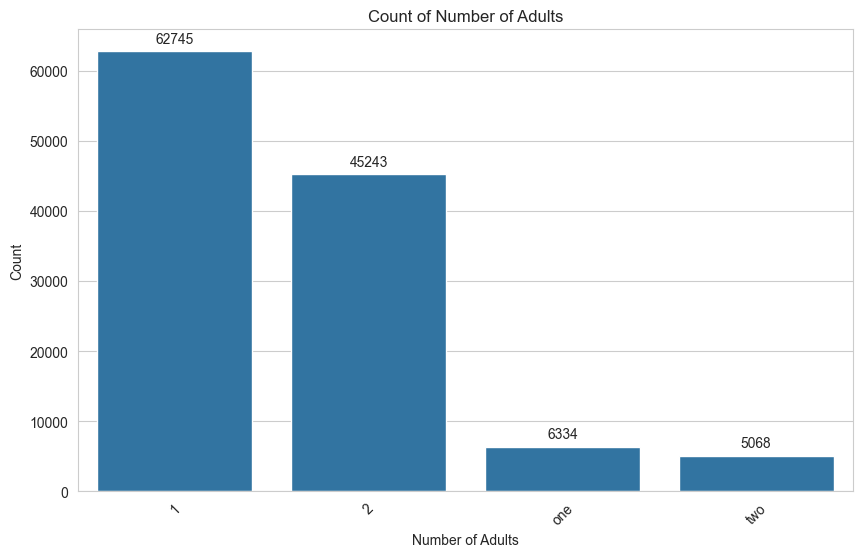

In [444]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for Number of Adults with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='num_adults', data=df)
plt.title('Count of Number of Adults')
plt.xlabel('Number of Adults')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

Mostly 1 adult

In [445]:
# Fix the Categorical Inconsistencies
# Replace 'one' with 1 and 'two' with 2 in the 'num_adults' column
df['num_adults'] = df['num_adults'].replace({'one': '1', 'two': '2'}).astype(int)

# Verify the changes
print(df['num_adults'].value_counts())

num_adults
1    69079
2    50311
Name: count, dtype: int64


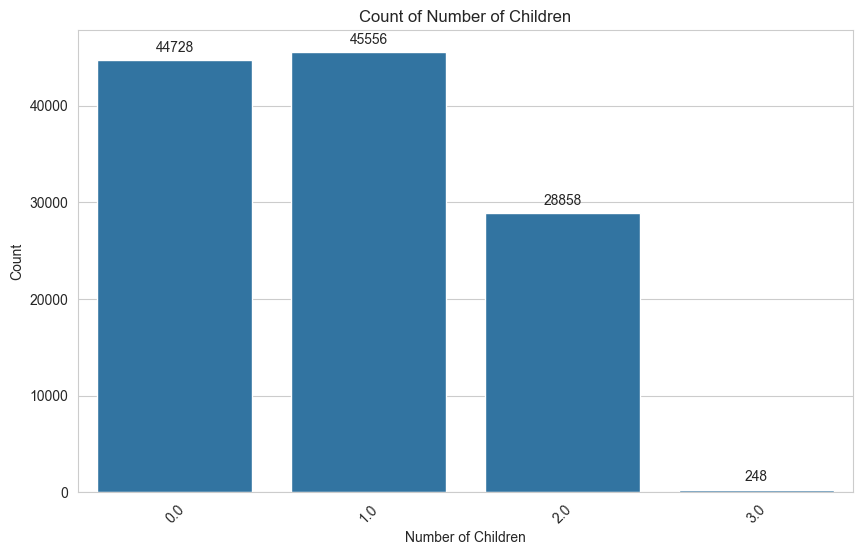

In [446]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for Number of Children with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='num_children', data=df)
plt.title('Count of Number of Children')
plt.xlabel('Number of Children')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

Mostly 0 and 1 child(ren)

Creating Histogram
------------------

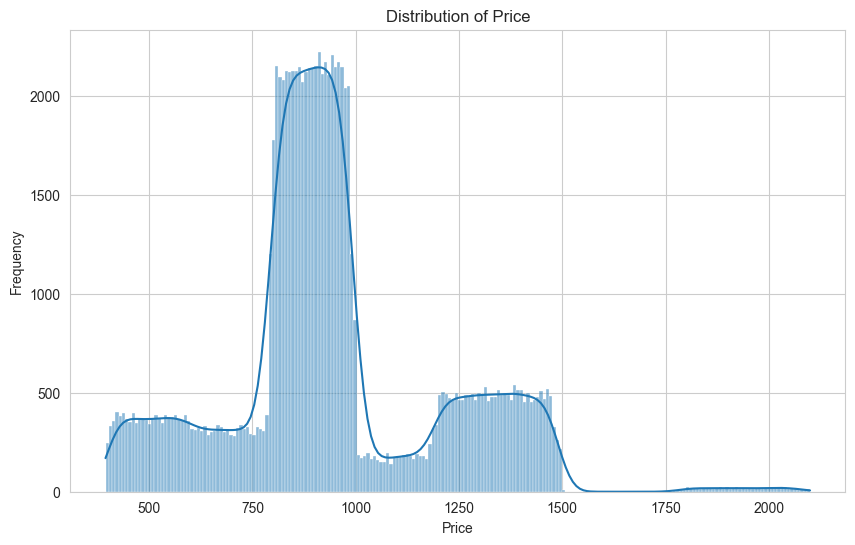

In [447]:
# Set the aesthetic style of the plots  
sns.set_style("whitegrid")  
  
# Histogram for price  
plt.figure(figsize=(10, 6))  
sns.histplot(df['price'], kde=True)  
plt.title('Distribution of Price')  
plt.xlabel('Price')  
plt.ylabel('Frequency')  
plt.show()

- 4 peaks. Correlates due to 4 room types

Creating Line Chart
-------------------

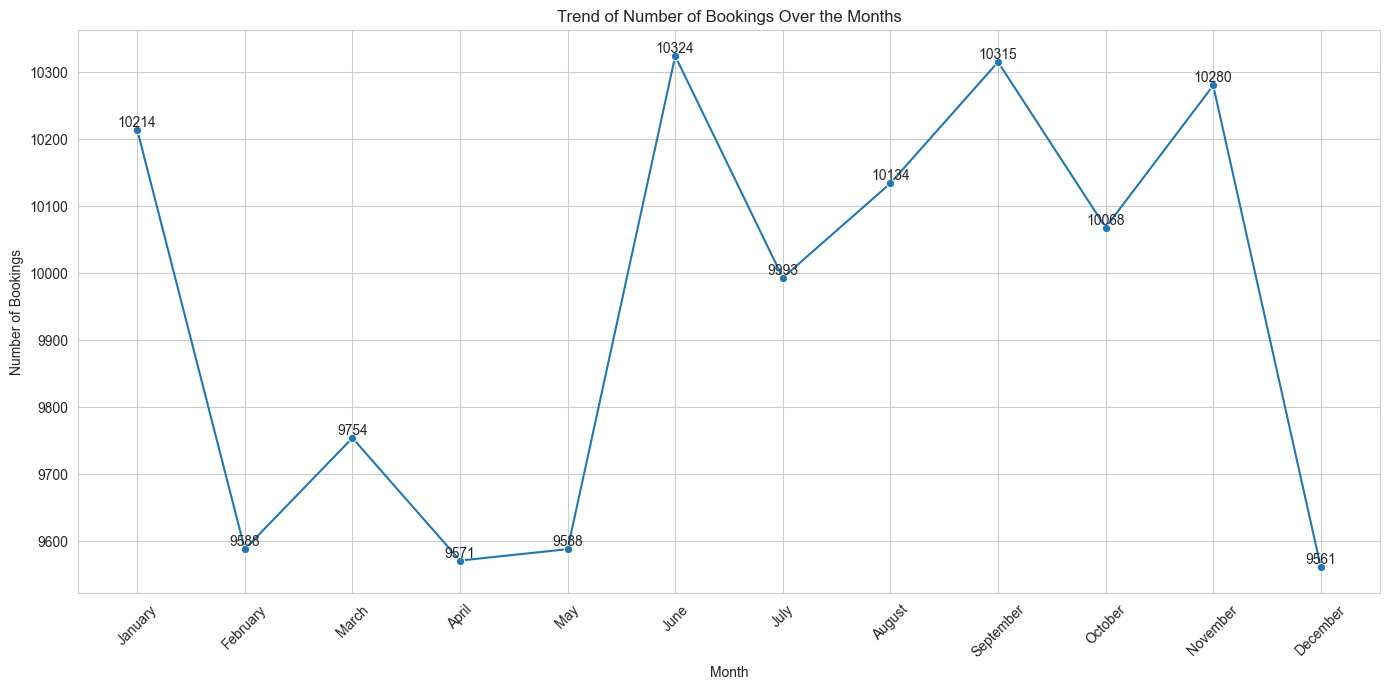

In [448]:
# Set Aesthetic Style
sns.set_style("whitegrid")

# Count the Number of Bookings by Month
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
month_counts = df['booking_month'].value_counts().reindex(month_order)

# Create the Line Chart
plt.figure(figsize=(14, 7))
line_plot = sns.lineplot(x=month_counts.index, y=month_counts.values, marker='o')

# Annotate the Data Points
for x, y in zip(month_counts.index, month_counts.values):
    plt.text(x, y, f'{y}', ha='center', va='bottom')

# Label the Chart
plt.title('Trend of Number of Bookings Over the Months')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Lower bookings in February, April, May, December

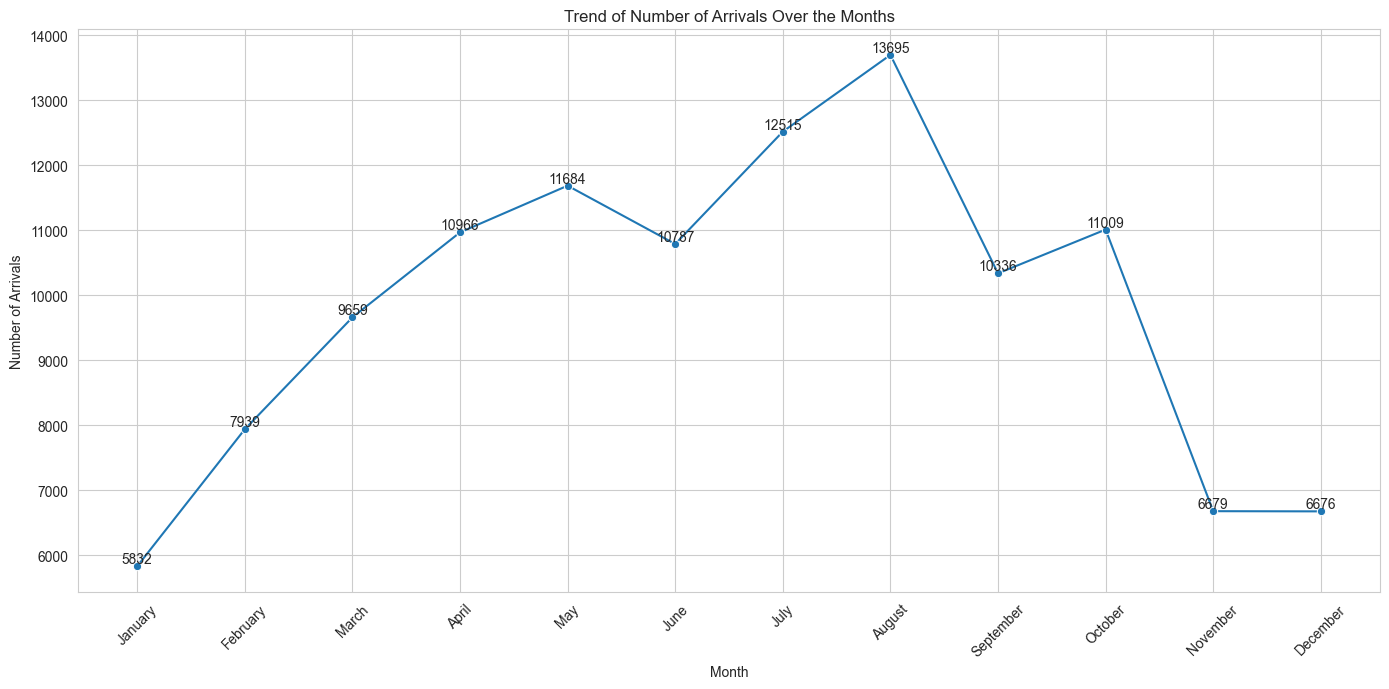

In [449]:
# Set Aesthetic Style
sns.set_style("whitegrid")

# Count the Number of Arrivals by Month
month_counts = df['arrival_month'].value_counts().reindex(month_order)

# Create the Line Chart
plt.figure(figsize=(14, 7))
line_plot = sns.lineplot(x=month_counts.index, y=month_counts.values, marker='o')

# Annotate the Data Points
for x, y in zip(month_counts.index, month_counts.values):
    plt.text(x, y, f'{y}', ha='center', va='bottom')

# Label the Chart
plt.title('Trend of Number of Arrivals Over the Months')
plt.xlabel('Month')
plt.ylabel('Number of Arrivals')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- Labelling capitalization error for 'arrival_month'

In [450]:
# Fix capitalization error
df['arrival_month'] = df['arrival_month'].str.title()

# Verify the changes
print(df['arrival_month'].value_counts())

arrival_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794
December      6780
January       5929
Name: count, dtype: int64


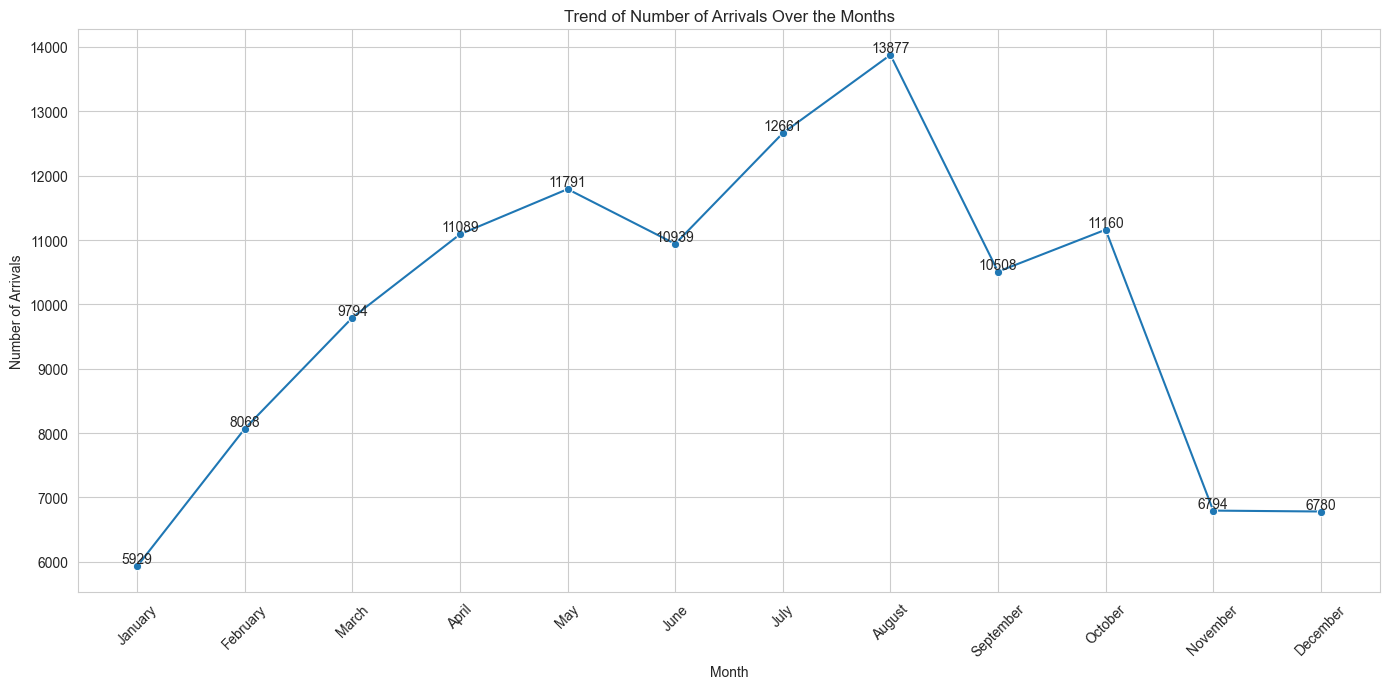

In [451]:
# Set Aesthetic Style
sns.set_style("whitegrid")

# Count the Number of Arrivals by Month
month_counts = df['arrival_month'].value_counts().reindex(month_order)

# Create the Line Chart
plt.figure(figsize=(14, 7))
line_plot = sns.lineplot(x=month_counts.index, y=month_counts.values, marker='o')

# Annotate the Data Points
for x, y in zip(month_counts.index, month_counts.values):
    plt.text(x, y, f'{y}', ha='center', va='bottom')

# Label the Chart
plt.title('Trend of Number of Arrivals Over the Months')
plt.xlabel('Month')
plt.ylabel('Number of Arrivals')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Lower arrivals in January, November, December

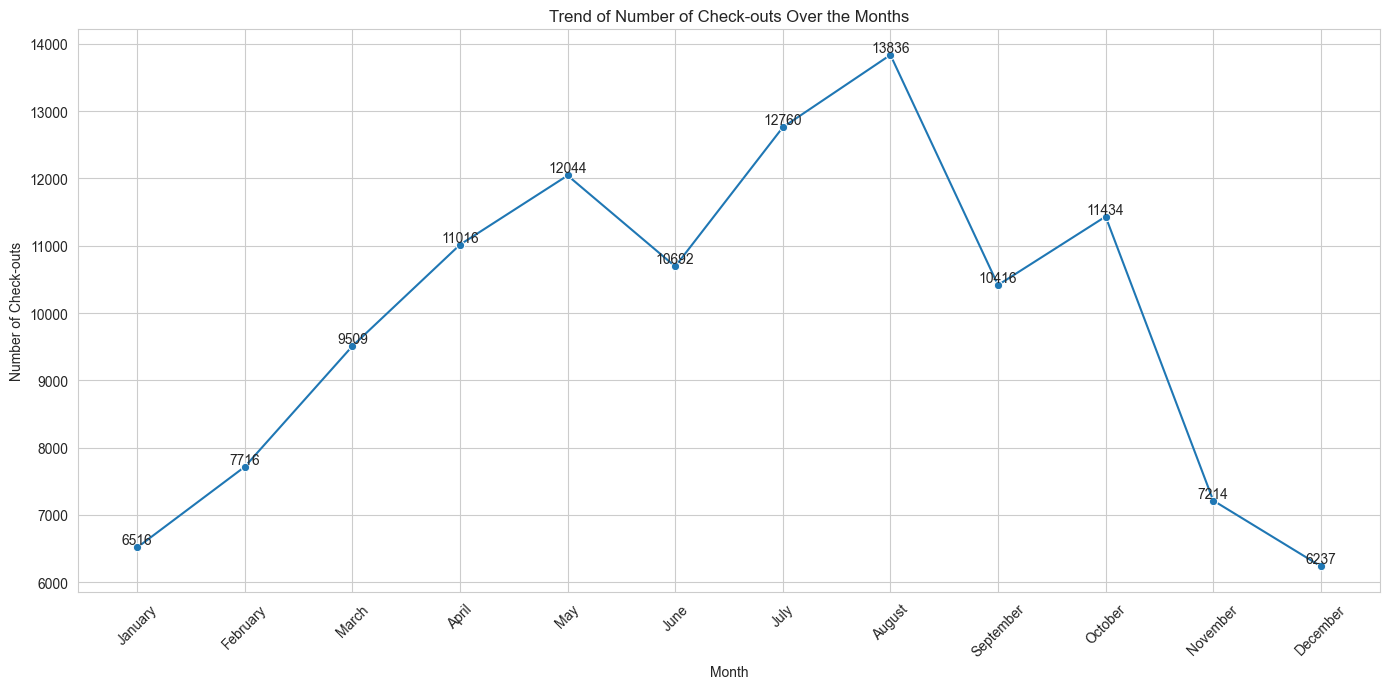

In [452]:
# Set Aesthetic Style
sns.set_style("whitegrid")

# Count the Number of Check-outs by Month
month_counts = df['checkout_month'].value_counts().reindex(month_order)

# Create the Line Chart
plt.figure(figsize=(14, 7))
line_plot = sns.lineplot(x=month_counts.index, y=month_counts.values, marker='o')

# Annotate the Data Points
for x, y in zip(month_counts.index, month_counts.values):
    plt.text(x, y, f'{y}', ha='center', va='bottom')

# Label the Chart
plt.title('Trend of Number of Check-outs Over the Months')
plt.xlabel('Month')
plt.ylabel('Number of Check-outs')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- Similar patten to arrival_month
- Indicating short hotel stays
- No clear patten with respect to booking_month

Creating a Box Plot
---------------------------

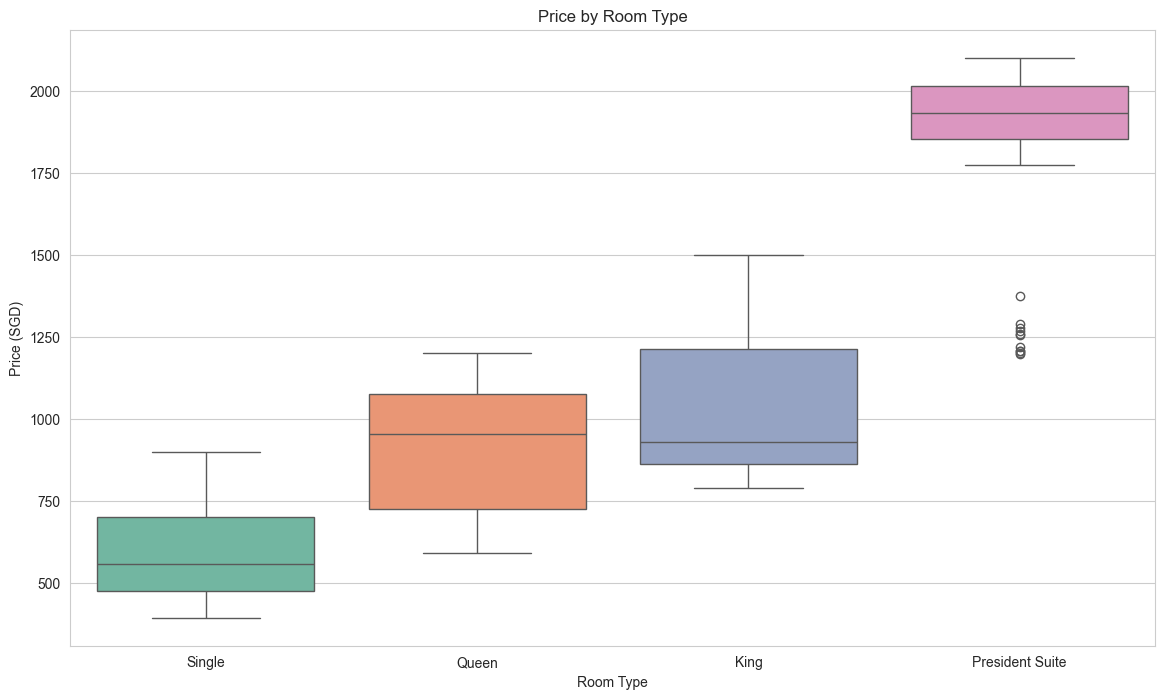

In [453]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")
room_order = ['Single', 'Queen', 'King', 'President Suite']

# Box plot for room vs price
plt.figure(figsize=(14, 8))
sns.boxplot(x='room', y='price', data=df, order=room_order,
            hue='room', hue_order=room_order, palette='Set2', legend=False)
plt.title('Price by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Price (SGD)')
plt.xticks(rotation=0)
plt.show()

- Price increases with room type
- Median price increases with room type in general, except for Queen and King
- IQR is smaller for president suite, suggesting more consistent pricing
- IQR larger for queen and king - greater variability in prices
- Presence of outliers for President Suite

In [454]:
# check if null values of 'room' and 'price' are independent from each other
print((df['room'].isna() & df['price'].isna()).sum())

0


Null values of 'room' and 'price' are independent of each other.

### Feature Engineering - 'booking_month' and 'arrival_month'

In [455]:
from typing import Optional

def months_before_arrival(row: pd.Series) -> Optional[int]:
    """
    Calculates the number of months between a customer's booking month and arrival month.

    The function takes a row containing 'booking_month' and 'arrival_month' as full month
    names, converts each to its month number (1-12), and returns the difference. Since the
    data has no year, the difference wraps around the calendar, so a booking made in
    November for a June arrival is 7 months ahead, not -5.

    Args:
        row (pd.Series): A row of the dataframe containing the columns 'booking_month'
            and 'arrival_month', each a full month name such as 'January'.

    Returns:
        Optional[int]: The number of months (0 to 11) between booking and arrival, or None
            if either month is missing or not a recognised month name.

    Example:
        months_before_arrival(row) -> 7
        (where row['booking_month'] = 'November' and row['arrival_month'] = 'June')
    """

    MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
    MONTH_NUM = {m: i for i, m in enumerate(MONTHS, start=1)}

    booked = MONTH_NUM.get(row['booking_month'])
    arrival = MONTH_NUM.get(row['arrival_month'])

    if booked is None or arrival is None:
        return pd.NA

    return (arrival - booked) % 12

df['lead_time_months'] = df.apply(months_before_arrival, axis=1).astype('Int64')

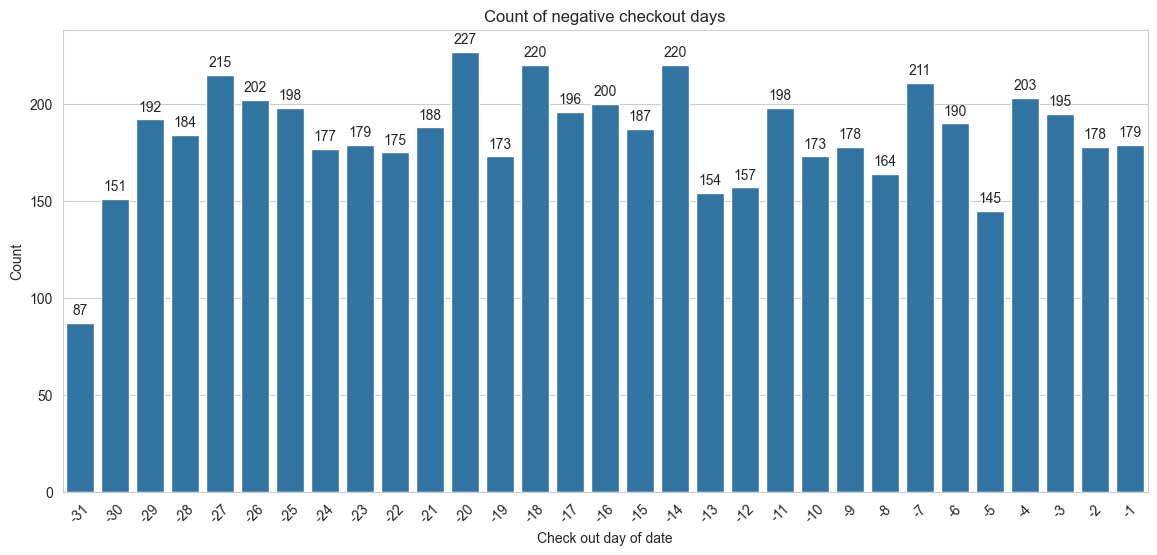

In [456]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Keep only checkout days <= 0 (as whole numbers, so labels read -23 instead of -23.0)
neg_days = df.loc[df['checkout_day'] <= 0, 'checkout_day'].astype(int)

# Bar chart for negative checkout days with annotations
plt.figure(figsize=(14, 6))
count_plot = sns.countplot(x=neg_days, order=sorted(neg_days.unique()))
plt.title('Count of negative checkout days')
plt.xlabel('Check out day of date')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center',
                        xytext=(0, 9),
                        textcoords='offset points')

plt.show()

In [457]:
from typing import Optional
import pandas as pd

def days_stayed(row: pd.Series) -> Optional[int]:
    """
    Calculates the number of days a customer stays at the hotel.

    The function takes a row containing the arrival and checkout month names and day dates,
    converts each date into its day position within a year, and returns the difference.
    Negative day values are treated as sign errors and converted to positive. A leap year
    (366 days) is assumed so that 29 February is accepted, and the difference wraps around
    the calendar, so arriving on 30 December and checking out on 2 January is a stay of 3 days.

    Args:
        row (pd.Series): A row of the dataframe containing the columns 'arrival_month',
            'arrival_day', 'checkout_month' and 'checkout_day'. The months are month
            names such as 'January' (any capitalisation) and the days are numbers.

    Returns:
        Optional[int]: The number of days between arrival and checkout, or None if any
            value is missing, the month is not recognised, or the day is not a valid date
            for that month.

    Example:
        days_stayed(row) -> 2
        (where row['arrival_month'] = 'June', row['arrival_day'] = 25.0,
        row['checkout_month'] = 'June' and row['checkout_day'] = -27.0)
    """
    months = ['January', 'February', 'March', 'April', 'May', 'June',
              'July', 'August', 'September', 'October', 'November', 'December']
    days_in_month = [31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

    def day_of_year(month, day):
        if pd.isna(month) or pd.isna(day):
            return None
        month = str(month).strip().title()
        if month not in months:
            return None
        idx = months.index(month)
        day = int(abs(day))
        if not 1 <= day <= days_in_month[idx]:
            return None
        return sum(days_in_month[:idx]) + day

    arrival = day_of_year(row['arrival_month'], row['arrival_day'])
    checkout = day_of_year(row['checkout_month'], row['checkout_day'])

    if arrival is None or checkout is None:
        return None

    return (checkout - arrival) % 366

df['days_stayed'] = df.apply(days_stayed, axis=1).astype('Int64')

In [458]:
df.isnull().sum()

booking_id              0
no_show                 0
branch                  0
booking_month           0
arrival_month           0
arrival_day             0
checkout_month          0
checkout_day            0
country                 0
first_time              0
room                21612
price               24881
platform                0
num_adults              0
num_children            0
currency            24881
lead_time_months        0
days_stayed             0
dtype: int64

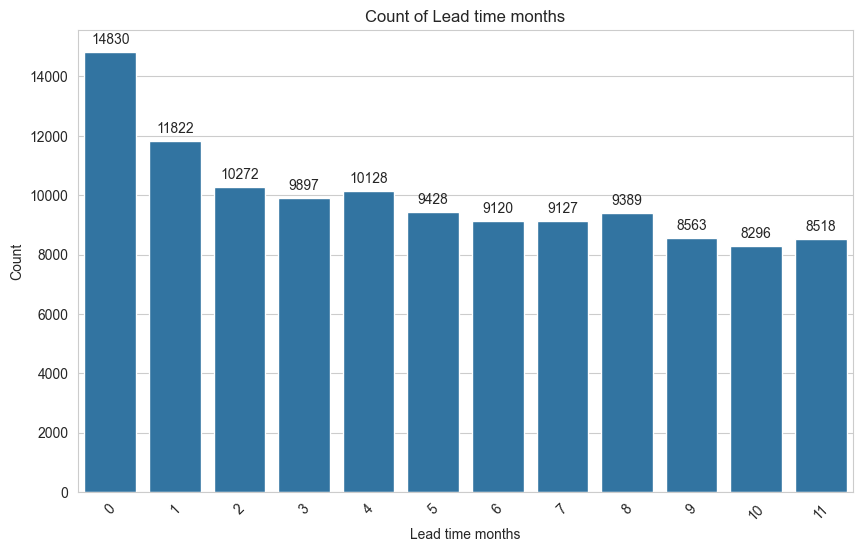

In [459]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for Number of Children with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='lead_time_months', data=df)
plt.title('Count of Lead time months')
plt.xlabel('Lead time months')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

General trend more bookings closer to arrival date

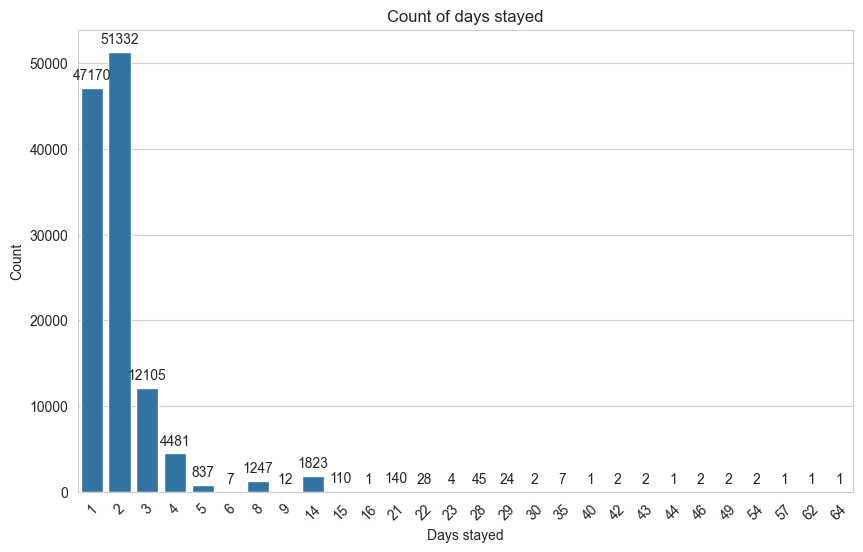

In [460]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for Number of Children with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='days_stayed', data=df)
plt.title('Count of days stayed')
plt.xlabel('Days stayed')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

- Days stayed mostly 1 to 2 days

Creating a Scatter Plot
---------------------------

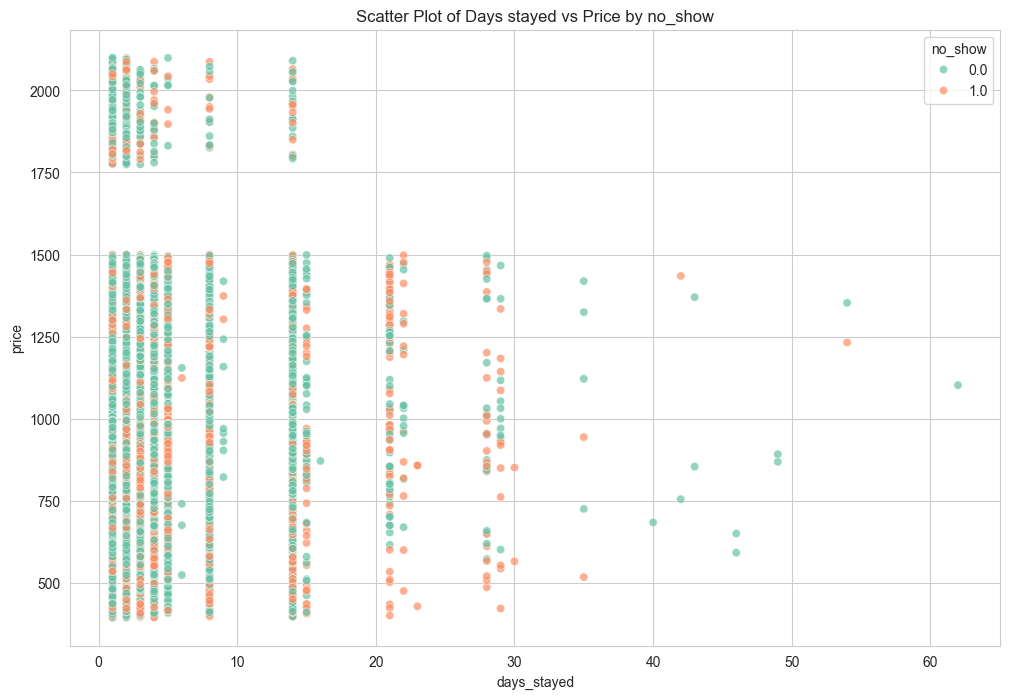

In [461]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Scatter plot for floor area vs resale price with color encoding for flat type
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df, x='days_stayed', y='price', hue='no_show', palette='Set2', alpha=0.7)
plt.title('Scatter Plot of Days stayed vs Price by no_show')
plt.xlabel('days_stayed')
plt.ylabel('price')
plt.legend(title='no_show')
plt.show()

- Positive trend as price, higher price for more days stayed
- Outliers days stayed above 30 days and price above 500 SGD.

In [462]:
# Filter the data for outliers
outliers = df[(df['days_stayed'] > 30) & (df['price'] > 500)]

# Display the outliers
outliers

,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children,currency,lead_time_months,days_stayed
9319,17942,0.0,Orchard,March,January,26.0,March,6.0,Australia,Yes,Single,683.99,Website,1,0.0,SGD$,10,40
14899,75124,1.0,Orchard,November,January,12.0,February,23.0,China,Yes,King,1434.94,Website,2,2.0,USD$,2,42
15659,66290,0.0,Changi,November,March,11.0,April,29.0,China,Yes,King,868.81,Website,2,1.0,USD$,4,49
23688,62165,1.0,Changi,October,January,15.0,February,19.0,Indonesia,Yes,King,943.89,Agent,1,1.0,USD$,3,35
31667,25712,1.0,Orchard,March,January,10.0,March,4.0,China,Yes,NaN,1232.39,Email,2,1.0,USD$,10,54
34986,72708,0.0,Orchard,March,August,1.0,October,2.0,Indonesia,Yes,Queen,1102.10,Website,1,0.0,SGD$,5,62
44152,5623,1.0,Changi,October,January,15.0,February,19.0,Indonesia,Yes,Single,517.52,Website,1,1.0,SGD$,3,35
51950,1669,0.0,Changi,February,January,15.0,February,27.0,Singapore,Yes,King,854.16,Website,2,1.0,USD$,11,43
55791,57333,0.0,Orchard,August,February,26.0,April,12.0,Australia,Yes,Single,650.21,Website,1,0.0,SGD$,6,46
63721,81346,0.0,Orchard,February,January,10.0,March,4.0,Australia,Yes,King,1352.84,Website,2,2.0,SGD$,11,54


- Outliers are all no_shows
- prices of these rooms vary significantly

## Correlation Analysis

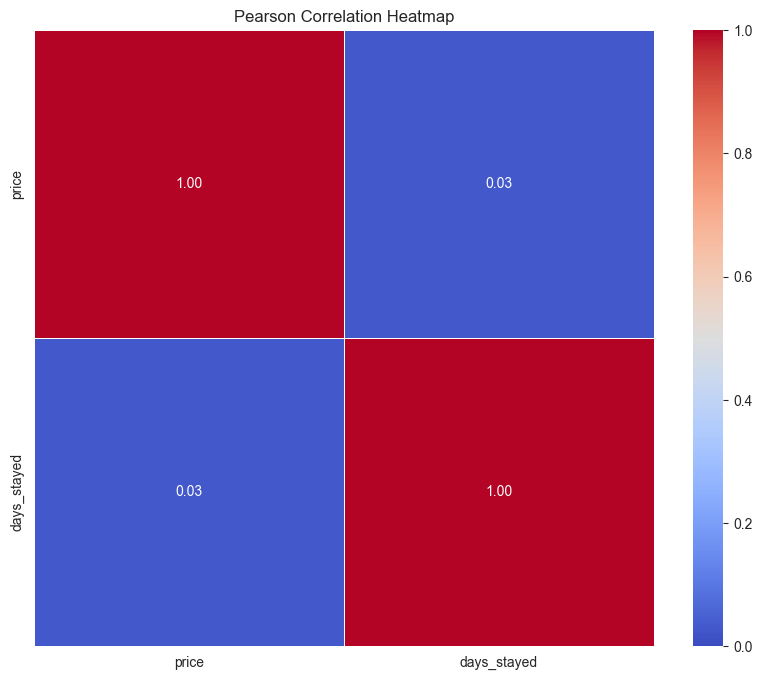

In [463]:
# Select continuous variables  
continuous_vars_all = df[['price', 'days_stayed']]

# Calculate the Pearson correlation matrix for the entire dataset
corr_matrix_pear = continuous_vars_all.corr(method='pearson')

# Plot the heatmap of the correlation matrix for the entire dataset
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix_pear, annot=True, cmap='coolwarm', vmin=0, center=0.5, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Pearson Correlation Heatmap')
plt.show()

no positive correlation berween 'days_stayed' and 'price'

In [464]:
baseline = df['no_show'].mean()
print(f'Baseline no-show rate: {baseline:.3f}\n')

for col in ['branch', 'country', 'platform', 'first_time', 'room', 'num_adults', 'num_children']:
    summary = df.groupby(col)['no_show'].agg(['mean', 'count'])
    summary['diff_from_baseline'] = summary['mean'] - baseline
    print(summary.sort_values('mean', ascending=False), '\n')

# Numeric features: compare distributions for show vs no-show
print(df.groupby('no_show')[['price', 'days_stayed', 'lead_time_months']].describe().T)

Baseline no-show rate: 0.370

             mean  count  diff_from_baseline
branch                                      
Changi   0.417270  79330            0.046853
Orchard  0.277634  40060           -0.092783 

               mean  count  diff_from_baseline
country                                       
China      0.566351  48590            0.195935
Malaysia   0.353956   3766           -0.016460
Indonesia  0.267085  25812           -0.103331
Singapore  0.240031   3912           -0.130386
India      0.220456  15790           -0.149960
Australia  0.202243  12129           -0.168174
Japan      0.170908   9391           -0.199508 

              mean  count  diff_from_baseline
platform                                     
Email     0.374571  32608            0.004154
Agent     0.369864  21735           -0.000552
Website   0.369694  54234           -0.000722
Phone     0.362619  10813           -0.007797 

                mean   count  diff_from_baseline
first_time                          

Strong signals (large gaps from baseline ~37%)

- country: strongest feature. China is at 57%, while Japan (17%), Australia (20%), India (22%) and Singapore (24%) are far below
- branch: Changi (42%) has a much higher no-show rate than Orchard (28%), and both have large counts
- first_time: Returning customers (No) no-show at 14%, compared with 38% for first-timers

Moderate signals

- lead_time_months: No-shows book earlier on average (5.4 vs 4.8 months, median 5 vs 4). Booking further ahead goes with a higher chance of not showing up, which is plausible because plans change.
- room: King is highest (39%), with Queen and Single around 31-32%.

Weak or no signal

- platform: All four platforms sit between 36% and 37.5%. This feature barely separates anything.
- num_adults (36.4% vs 37.9%), num_children (36-39%) and days_stayed: The differences are tiny
- price: The means are close

In [465]:
# Drop irrelevant columns
df.drop(columns=['booking_id', 'booking_month', 'arrival_day',
                 'checkout_month', 'checkout_day', 'currency'], inplace=True)

### Preparing the classification Target Variable

In [466]:
# Check the distribution of the target column
df['no_show'].value_counts()

no_show
0.0    75166
1.0    44224
Name: count, dtype: int64

In [467]:
from sklearn.model_selection import train_test_split

# Separate the data into features and target
X = df.drop(columns='no_show')
y = df['no_show']

# Split the data into training (80%) and test-validation (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [468]:
# Display the shapes of the splits to verify
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (95512, 11) (95512,)
Validation set shape: (11939, 11) (11939,)
Test set shape: (11939, 11) (11939,)


In [469]:
def log_class_distribution(y_split, name):
    counts = y_split.value_counts().sort_index()
    props = y_split.value_counts(normalize=True).sort_index()
    out = pd.DataFrame({'count': counts, 'proportion': props.round(4)})
    print(f'--- {name} (n={len(y_split)}) ---')
    print(out, '\n')

log_class_distribution(y, 'Full dataset')
log_class_distribution(y_train, 'Train')
log_class_distribution(y_test, 'Test')

--- Full dataset (n=119390) ---
         count  proportion
no_show                   
0.0      75166      0.6296
1.0      44224      0.3704 

--- Train (n=95512) ---
         count  proportion
no_show                   
0.0      60133      0.6296
1.0      35379      0.3704 

--- Test (n=11939) ---
         count  proportion
no_show                   
0.0       7517      0.6296
1.0       4422      0.3704 



**Imbalance strategy:** The target is moderately imbalanced (about 37% no-show, 63% show,
a ratio of roughly 1.7:1). I am **not applying resampling** (no oversampling, undersampling
or SMOTE), because the imbalance is mild and resampling risks overfitting (oversampling) or
discarding data (undersampling). Instead I use stratified splits to preserve the class ratio
in train, test and every CV fold, and I evaluate with precision, recall, F1 and ROC-AUC
instead of accuracy.

In [470]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Define numerical features to be standardized
numerical_features = ['price', 'days_stayed']

# Create a numerical transformer pipeline
numerical_transformer = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

## Feature Encoding

In [471]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Define nomial features to be one-hot encoded
nominal_features = ['branch', 'country', 'first_time', 'platform', 'arrival_month']

# Define ordinal features to be ordinally encoded
ordinal_features = ['room','num_adults','num_children']

# Define the ordinal categories for flat_type
room_categories = ['Single', 'Queen', 'King', 'President Suite']
num_adults_categories = [1, 2]
num_children_categories = [0, 1, 2, 3]

# Define passthrough features that will not be transformed
passthrough_features = ['lead_time_months']

# Create a nominal transformer pipeline
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Create an ordinal transformer pipeline
ordinal_transformer = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=[room_categories, num_adults_categories, num_children_categories], handle_unknown='use_encoded_value', unknown_value=-1))  
])

In [472]:
from sklearn.compose import ColumnTransformer

# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('nom', nominal_transformer, nominal_features),
        ('ord', ordinal_transformer, ordinal_features),
        ('pass', 'passthrough', passthrough_features) # Pass through the storey_range feature without transformation
    ],
    remainder='passthrough',
    n_jobs=-1
    )

## Logistic Regression

In [473]:
# Import the necessary library
from sklearn.linear_model import LogisticRegression

# Create the pipeline with a logistic regression model
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # Use the preprocessor pipeline defined earlier
    ('classifier', LogisticRegression(max_iter=1000))
])

# Fit the pipeline to the training data
logreg_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = logreg_pipeline.predict(X_val)

In [474]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate the classification metrics for Logistic Regression
logreg_val_accuracy = accuracy_score(y_val, y_val_pred)

# Display the metrics for Logistic Regression
print("Logistic Regression Metrics:")
print(f'LogReg Validation Accuracy: {logreg_val_accuracy:.5f}')

Logistic Regression Metrics:
LogReg Validation Accuracy: 0.72963


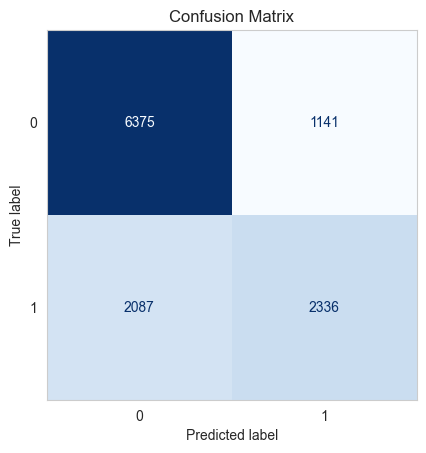

In [475]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
fig, ax = plt.subplots()
disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

In [476]:
# Calculate the classification metrics for Logistic Regression
logreg_val_precision = precision_score(y_val, y_val_pred)
logreg_val_recall = recall_score(y_val, y_val_pred)
logreg_val_f1 = f1_score(y_val, y_val_pred)

# Display the metrics for Logistic Regression
print("Logistic Regression Metrics:")
print(f'LogReg Validation Precision: {logreg_val_precision:.5f}')
print(f'LogReg Validation Recall: {logreg_val_recall:.5f}')
print(f'LogReg Validation F1 Score: {logreg_val_f1:.5f}')

Logistic Regression Metrics:
LogReg Validation Precision: 0.67184
LogReg Validation Recall: 0.52815
LogReg Validation F1 Score: 0.59139


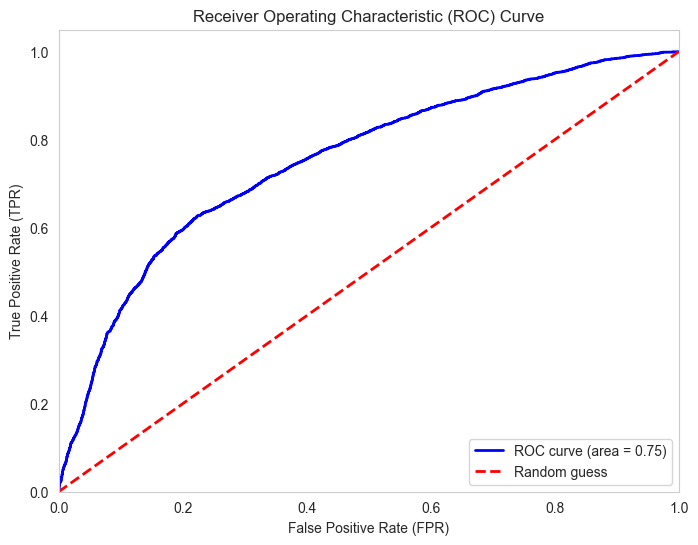

In [477]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt  

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, logreg_pipeline.predict_proba(X_val)[:, 1])

# Calculate the AUC
roc_auc = roc_auc_score(y_val, logreg_pipeline.predict_proba(X_val)[:, 1])

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate (FPR)')  
plt.ylabel('True Positive Rate (TPR)')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc='lower right')  
plt.grid()  
plt.show()

## KNN

In [478]:
from sklearn.neighbors import KNeighborsClassifier

# Create the pipeline with a KNN classifier
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # Use the preprocessor pipeline defined earlier
    ('classifier', KNeighborsClassifier(n_neighbors=5)) # You can choose the number of neighbors (k) as desired
])

# Fit the pipeline to the training data
knn_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = knn_pipeline.predict(X_val)
y_val_pred_proba = knn_pipeline.predict_proba(X_val)[:, 1]

In [479]:
# Calculate and print the classification metrics for the KNN model
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)
val_recall = recall_score(y_val, y_val_pred)
val_f1 = f1_score(y_val, y_val_pred)
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)

print("K-Nearest Neighbors (KNN) Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')

K-Nearest Neighbors (KNN) Metrics:
Validation Accuracy: 0.70282
Validation Precision: 0.61056
Validation Recall: 0.54624
Validation F1 Score: 0.57661
Validation ROC AUC: 0.72388


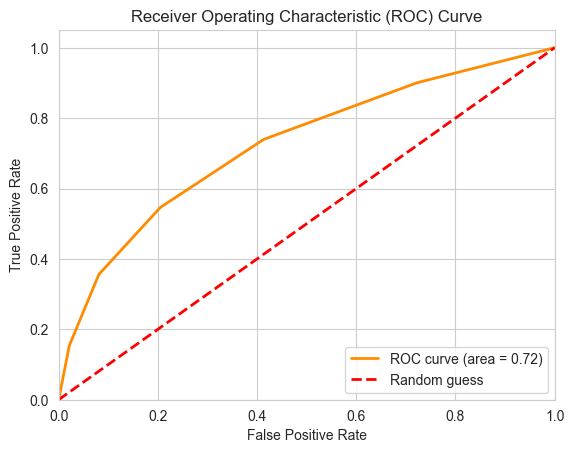

In [480]:
# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, knn_pipeline.predict_proba(X_val)[:, 1])
roc_auc = roc_auc_score(y_val, knn_pipeline.predict_proba(X_val)[:, 1])

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

## Decision tree

In [481]:
from sklearn.tree import DecisionTreeClassifier

# Create the pipeline with a Decision Tree classifier
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, max_depth=None, random_state=42))  
])

# Fit the pipeline to the training data
dt_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = dt_pipeline.predict(X_val)
y_val_pred_proba = dt_pipeline.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)  
val_recall = recall_score(y_val, y_val_pred)  
val_f1 = f1_score(y_val, y_val_pred)  
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)  

# Calculate metrics for the training set
y_train_pred = dt_pipeline.predict(X_train)  
y_train_pred_proba = dt_pipeline.predict_proba(X_train)[:, 1]  

train_accuracy = accuracy_score(y_train, y_train_pred)  
train_precision = precision_score(y_train, y_train_pred)  
train_recall = recall_score(y_train, y_train_pred)  
train_f1 = f1_score(y_train, y_train_pred)  
train_roc_auc = roc_auc_score(y_train, y_train_pred_proba)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')  

print("Training Set Metrics:")
print(f'Training Accuracy: {train_accuracy:.5f}')  
print(f'Training Precision: {train_precision:.5f}')  
print(f'Training Recall: {train_recall:.5f}')  
print(f'Training F1 Score: {train_f1:.5f}')  
print(f'Training ROC AUC: {train_roc_auc:.5f}')

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.65910
Validation Precision: 0.53964
Validation Recall: 0.54330
Validation F1 Score: 0.54146
Validation ROC AUC: 0.63951
Training Set Metrics:
Training Accuracy: 0.99246
Training Precision: 0.99670
Training Recall: 0.98290
Training F1 Score: 0.98975
Training ROC AUC: 0.99987


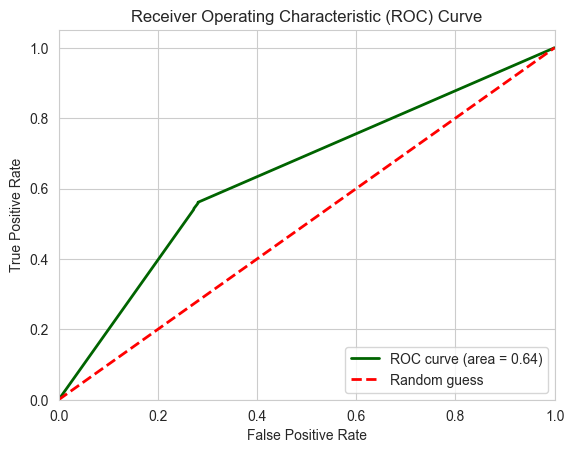

In [482]:
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba)
roc_auc = roc_auc_score(y_val, y_val_pred_proba)

plt.figure()  
plt.plot(fpr, tpr, color='darkgreen', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

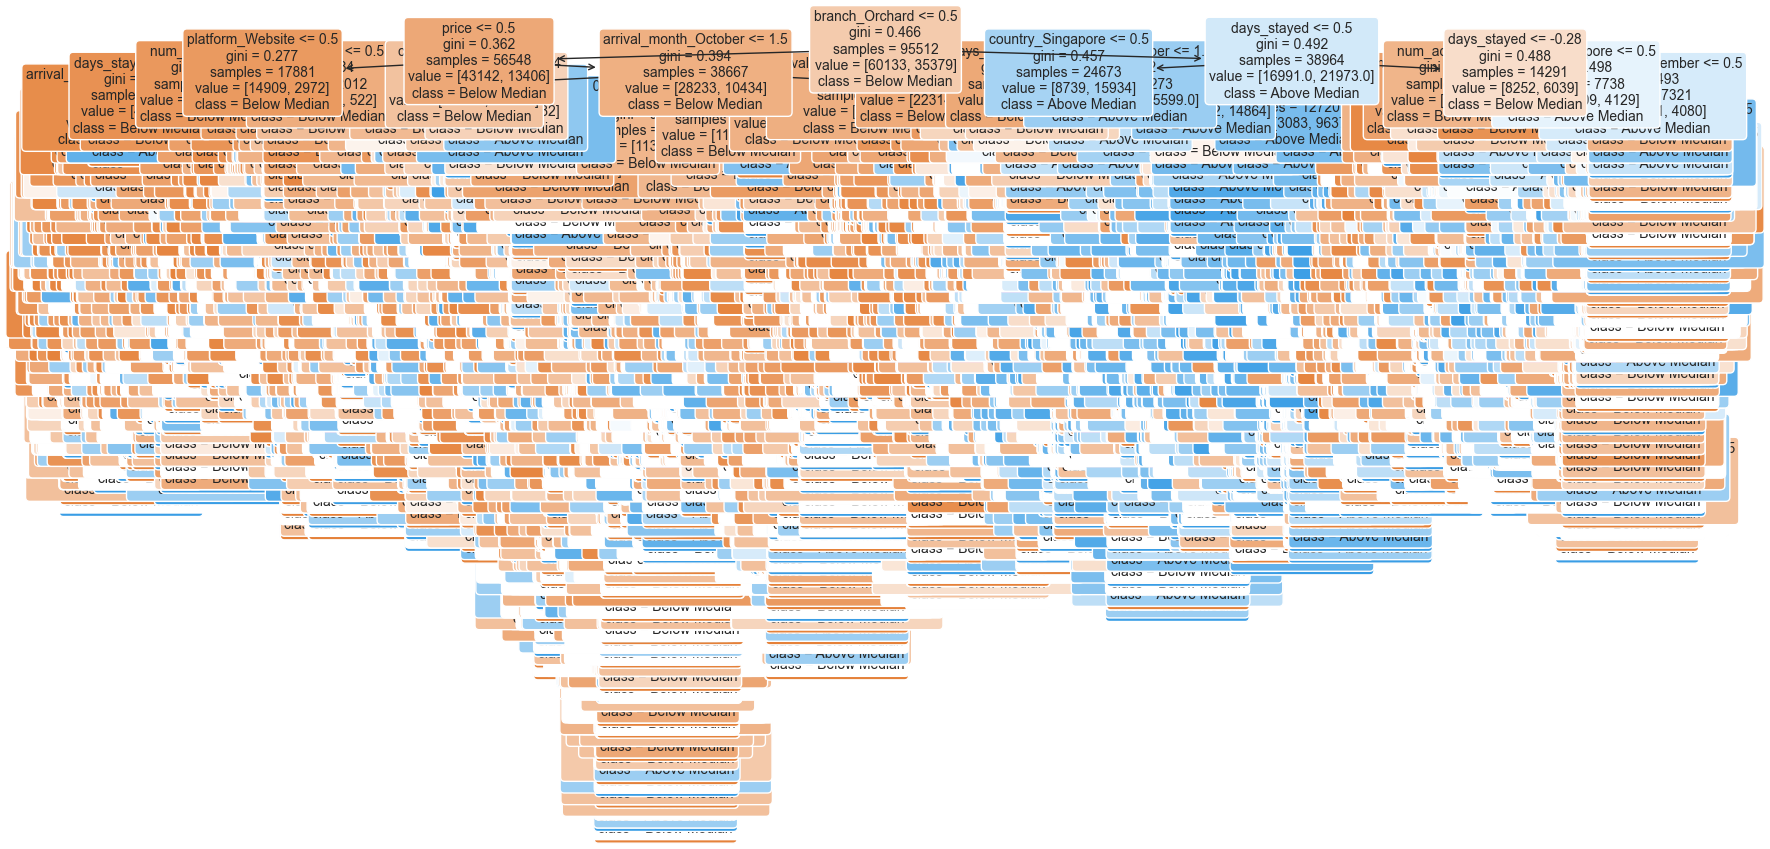

In [483]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract the transformed feature names
feature_names = []
for name, transformer, columns in dt_pipeline.named_steps['preprocessor'].transformers_:
    if hasattr(transformer, 'named_steps'):
        for step in transformer.named_steps.values():
            if hasattr(step, 'get_feature_names_out'):
                feature_names.extend(step.get_feature_names_out(columns))
    elif hasattr(transformer, 'get_feature_names_out'):
        feature_names.extend(transformer.get_feature_names_out(columns))
    else:
        feature_names.extend(columns)
				
# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(dt_pipeline.named_steps['classifier'], feature_names=feature_names, class_names=['Below Median', 'Above Median'], filled=True, rounded=True, fontsize=10)
plt.show()

### Pruning

In [484]:
# Create the new pipeline with a Decision Tree classifier with new max_depth pre-pruning parameter
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, max_depth=5, min_samples_leaf=1, random_state=42))
])  

# Fit the pipeline to the training data
dt_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = dt_pipeline.predict(X_val)
y_val_pred_proba = dt_pipeline.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)  
val_recall = recall_score(y_val, y_val_pred)  
val_f1 = f1_score(y_val, y_val_pred)  
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)  

# Calculate metrics for the training set
y_train_pred = dt_pipeline.predict(X_train)  
y_train_pred_proba = dt_pipeline.predict_proba(X_train)[:, 1]  

train_accuracy = accuracy_score(y_train, y_train_pred)  
train_precision = precision_score(y_train, y_train_pred)  
train_recall = recall_score(y_train, y_train_pred)  
train_f1 = f1_score(y_train, y_train_pred)  
train_roc_auc = roc_auc_score(y_train, y_train_pred_proba)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')  

print("Training Set Metrics:")
print(f'Training Accuracy: {train_accuracy:.5f}')  
print(f'Training Precision: {train_precision:.5f}')  
print(f'Training Recall: {train_recall:.5f}')  
print(f'Training F1 Score: {train_f1:.5f}')  
print(f'Training ROC AUC: {train_roc_auc:.5f}')

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.73582
Validation Precision: 0.67919
Validation Recall: 0.54375
Validation F1 Score: 0.60397
Validation ROC AUC: 0.75322
Training Set Metrics:
Training Accuracy: 0.72726
Training Precision: 0.66216
Training Recall: 0.53837
Training F1 Score: 0.59388
Training ROC AUC: 0.74982


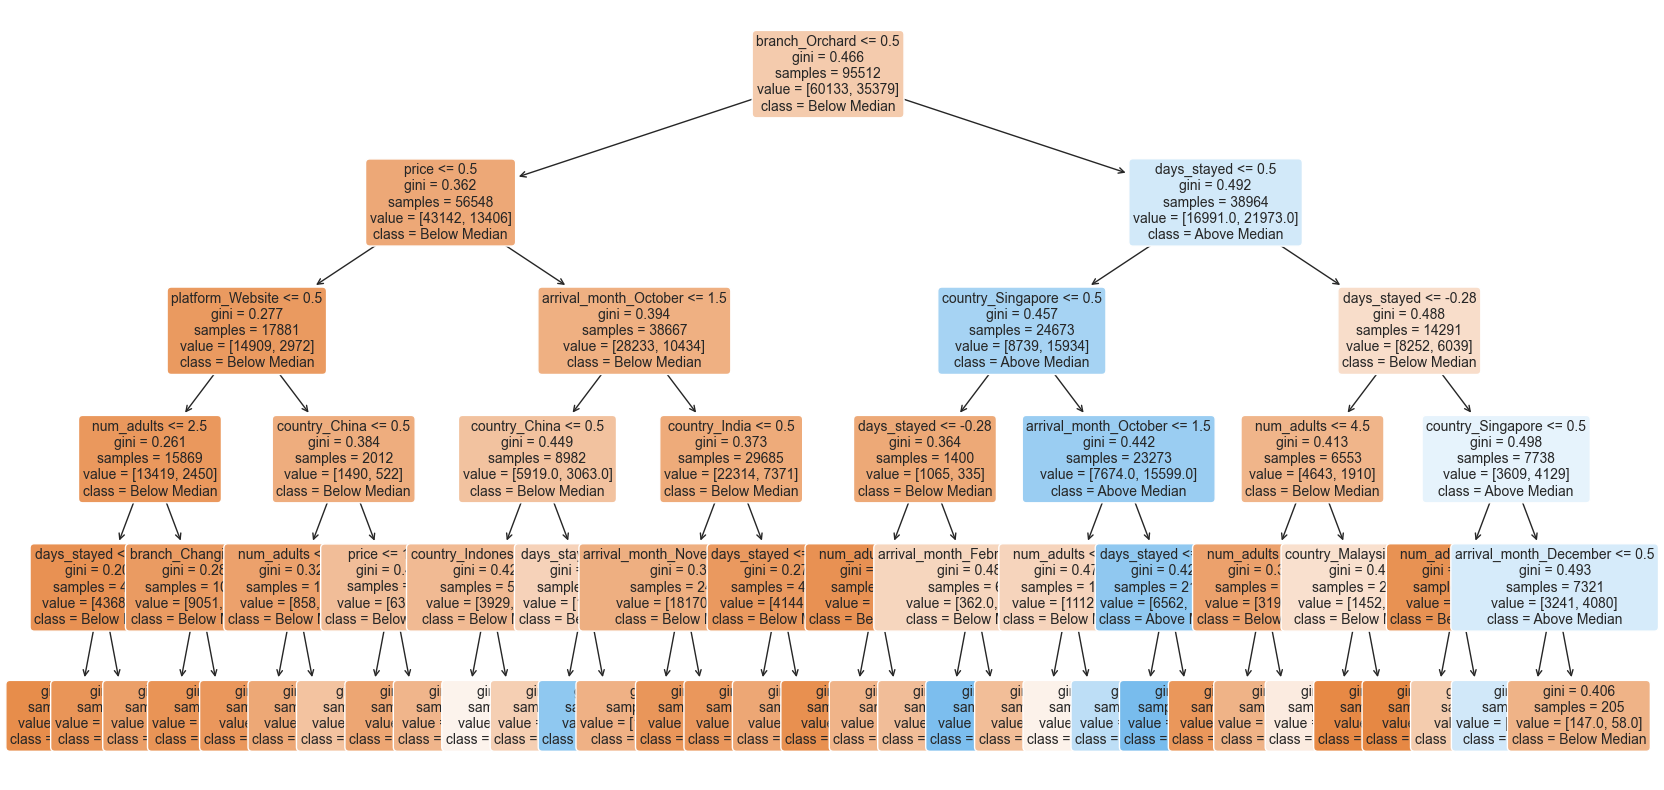

In [485]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract the transformed feature names
feature_names = []
for name, transformer, columns in dt_pipeline.named_steps['preprocessor'].transformers_:
    if hasattr(transformer, 'named_steps'):
        for step in transformer.named_steps.values():
            if hasattr(step, 'get_feature_names_out'):
                feature_names.extend(step.get_feature_names_out(columns))
    elif hasattr(transformer, 'get_feature_names_out'):
        feature_names.extend(transformer.get_feature_names_out(columns))
    else:
        feature_names.extend(columns)
				
# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(dt_pipeline.named_steps['classifier'], feature_names=feature_names, class_names=['Below Median', 'Above Median'], filled=True, rounded=True, fontsize=10)
plt.show()

In [486]:
from sklearn.model_selection import GridSearchCV

logreg_param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1.0, 10, 100, 1000],
    'classifier__penalty': ['l2', None]
}

logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # Use the preprocessor pipeline defined earlier
    ('classifier', LogisticRegression(max_iter=1000))
])

knn_param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 15],
    'classifier__weights': ['uniform', 'distance']
}

knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # Use the preprocessor pipeline defined earlier
    ('classifier', KNeighborsClassifier()) # You can choose the number of neighbors (k) as desired
])

dt_param_grid = {
    'classifier__max_depth': [3, 5, 7, 10],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, min_samples_leaf=1, random_state=42))
])
# Perform grid search with cross-validation
logreg_grid_search = GridSearchCV(logreg_pipeline, logreg_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
logreg_grid_search.fit(X_train, y_train)

knn_grid_search = GridSearchCV(knn_pipeline, knn_param_grid, cv=5, scoring='accuracy', n_jobs=2)
knn_grid_search.fit(X_train, y_train)

dt_grid_search = GridSearchCV(dt_pipeline, dt_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
dt_grid_search.fit(X_train, y_train)

c:\Users\wongj\miniconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1186: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(n_jobs=-1,
                                                          remainder='passthrough',
                                                          transformers=[('num',
                                                                         Pipeline(steps=[('impute',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['price',
                                                                          'days_stayed']),
                                                                        ('nom',
                                                                         Pipeline(steps=[('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['branch',
                                                                          'country',
                                                                          'first_...
                                                                                                         handle_unknown='use_encoded_value',
                                                                                                         unknown_value=-1))]),
                                                                         ['room',
                                                                          'num_adults',
                                                                          'num_children']),
                                                                        ('pass',
                                                                         'passthrough',
                                                                         ['lead_time_months'])])),
                                       ('classifier',
                                        DecisionTreeClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [3, 5, 7, 10],
                         'classifier__min_samples_leaf': [1, 2, 4],
                         'classifier__min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [487]:
for name, gs in [('Logistic Regression', logreg_grid_search),
                 ('KNN', knn_grid_search),
                 ('Decision Tree', dt_grid_search)]:
    print(f"{name}\n  Best params: {gs.best_params_}\n  Best CV score: {gs.best_score_:.4f}\n")

Logistic Regression
  Best params: {'classifier__C': 0.001, 'classifier__penalty': None}
  Best CV score: 0.7216

KNN
  Best params: {'classifier__n_neighbors': 15, 'classifier__weights': 'uniform'}
  Best CV score: 0.7197

Decision Tree
  Best params: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10}
  Best CV score: 0.7370



Logistics Regression (KNN) Metrics:
Validation Accuracy: 0.72954
Validation Precision: 0.67165
Validation Recall: 0.52815
Validation F1 Score: 0.59132
Validation ROC AUC: 0.75280


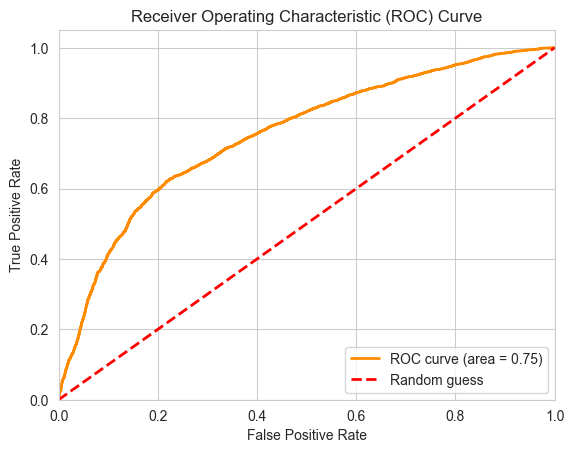

In [488]:
# Evaluate the best Logistic Regression model on the validation set
best_logreg_model = logreg_grid_search.best_estimator_
y_val_pred_logreg = best_logreg_model.predict(X_val)
y_val_pred_proba_logreg = best_logreg_model.predict_proba(X_val)[:, 1]

val_accuracy_logreg = accuracy_score(y_val, y_val_pred_logreg)
val_precision_logreg = precision_score(y_val, y_val_pred_logreg)
val_recall_logreg = recall_score(y_val, y_val_pred_logreg)
val_f1_logreg = f1_score(y_val, y_val_pred_logreg)
val_roc_auc_logreg = roc_auc_score(y_val, y_val_pred_proba_logreg)

print("Logistics Regression (KNN) Metrics:")
print(f'Validation Accuracy: {val_accuracy_logreg:.5f}')
print(f'Validation Precision: {val_precision_logreg:.5f}')  
print(f'Validation Recall: {val_recall_logreg:.5f}')  
print(f'Validation F1 Score: {val_f1_logreg:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc_logreg:.5f}')

# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba_logreg)
roc_auc = roc_auc_score(y_val, y_val_pred_proba_logreg)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

K-Nearest Neighbors (KNN) Metrics:
Validation Accuracy: 0.72736
Validation Precision: 0.66177
Validation Recall: 0.54013
Validation F1 Score: 0.59480
Validation ROC AUC: 0.75193


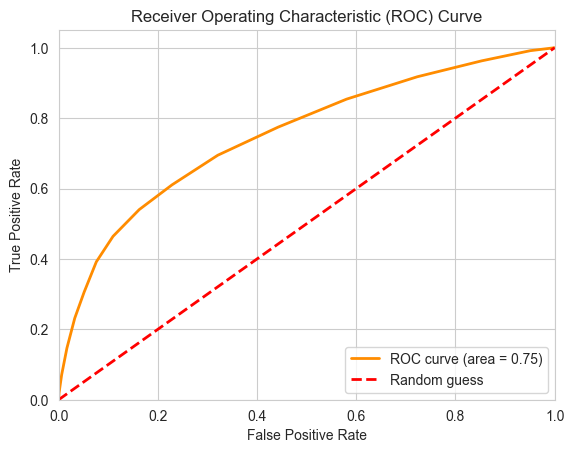

In [489]:
# Evaluate the best KNN model on the validation set
best_knn_model = knn_grid_search.best_estimator_
y_val_pred_knn = best_knn_model.predict(X_val)
y_val_pred_proba_knn = best_knn_model.predict_proba(X_val)[:, 1]

val_accuracy_knn = accuracy_score(y_val, y_val_pred_knn)
val_precision_knn = precision_score(y_val, y_val_pred_knn)
val_recall_knn = recall_score(y_val, y_val_pred_knn)
val_f1_knn = f1_score(y_val, y_val_pred_knn)
val_roc_auc_knn = roc_auc_score(y_val, y_val_pred_proba_knn)

print("K-Nearest Neighbors (KNN) Metrics:")
print(f'Validation Accuracy: {val_accuracy_knn:.5f}')
print(f'Validation Precision: {val_precision_knn:.5f}')  
print(f'Validation Recall: {val_recall_knn:.5f}')  
print(f'Validation F1 Score: {val_f1_knn:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc_knn:.5f}')

# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba_knn)
roc_auc = roc_auc_score(y_val, y_val_pred_proba_knn)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.74445
Validation Precision: 0.70070
Validation Recall: 0.54149
Validation F1 Score: 0.61089
Validation ROC AUC: 0.76979
Training Set Metrics:
Training Accuracy: 0.74910
Training Precision: 0.70739
Training Recall: 0.55027
Training F1 Score: 0.61901
Training ROC AUC: 0.78964


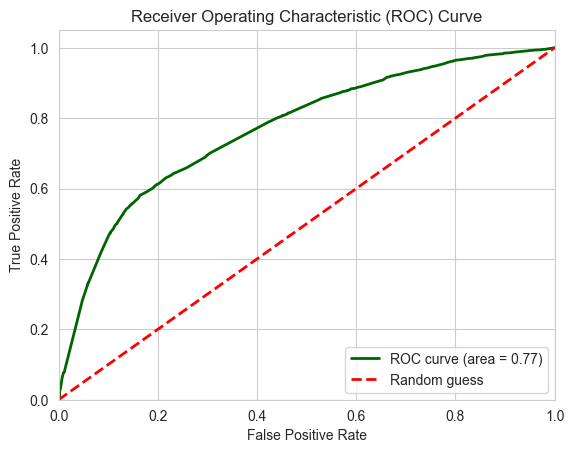

In [490]:
# Evaluate the best Decision tree model on the validation set
# Predict on the validation set
best_dt_model = dt_grid_search.best_estimator_
y_val_pred_dt = best_dt_model.predict(X_val)
y_val_pred_proba_dt = best_dt_model.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy_dt = accuracy_score(y_val, y_val_pred_dt)
val_precision_dt = precision_score(y_val, y_val_pred_dt)  
val_recall_dt = recall_score(y_val, y_val_pred_dt)  
val_f1_dt = f1_score(y_val, y_val_pred_dt)  
val_roc_auc_dt = roc_auc_score(y_val, y_val_pred_proba_dt)  

# Calculate metrics for the training set
y_train_pred_dt= best_dt_model.predict(X_train)  
y_train_pred_proba_dt = best_dt_model.predict_proba(X_train)[:, 1]  

train_accuracy_dt = accuracy_score(y_train, y_train_pred_dt)  
train_precision_dt = precision_score(y_train, y_train_pred_dt)  
train_recall_dt = recall_score(y_train, y_train_pred_dt)  
train_f1_dt = f1_score(y_train, y_train_pred_dt)  
train_roc_auc_dt = roc_auc_score(y_train, y_train_pred_proba_dt)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy_dt:.5f}')
print(f'Validation Precision: {val_precision_dt:.5f}')  
print(f'Validation Recall: {val_recall_dt:.5f}')  
print(f'Validation F1 Score: {val_f1_dt:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc_dt:.5f}')  

print("Training Set Metrics:")
print(f'Training Accuracy: {train_accuracy_dt:.5f}')  
print(f'Training Precision: {train_precision_dt:.5f}')  
print(f'Training Recall: {train_recall_dt:.5f}')  
print(f'Training F1 Score: {train_f1_dt:.5f}')  
print(f'Training ROC AUC: {train_roc_auc_dt:.5f}')

fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba_dt)
roc_auc = roc_auc_score(y_val, y_val_pred_proba_dt)

plt.figure()  
plt.plot(fpr, tpr, color='darkgreen', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()